In [1]:

import pandas as pd

# App usage dataset
data = {
    "login_days": [20, 3, 15, 2, 25, 7, 18, 4, 22, 5],
    "session_minutes": [45, 10, 35, 8, 60, 15, 40, 12, 55, 9],
    "features_used": [8, 2, 6, 1, 9, 3, 7, 2, 8, 2],
    "notifications_opened": [15, 1, 10, 0, 20, 3, 12, 1, 18, 2],
    "retained": [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
}

df = pd.DataFrame(data)

print("APP USAGE DATASET")
display(df)

print("\nDATASET SUMMARY")
display(df.describe())

print("\nRETENTION DISTRIBUTION")
print(df["retained"].value_counts().rename({
    0: "Not Retained",
    1: "Retained"
}))


APP USAGE DATASET


,login_days,session_minutes,features_used,notifications_opened,retained
0,20,45,8,15,1
1,3,10,2,1,0
2,15,35,6,10,1
3,2,8,1,0,0
4,25,60,9,20,1
5,7,15,3,3,0
6,18,40,7,12,1
7,4,12,2,1,0
8,22,55,8,18,1
9,5,9,2,2,0



DATASET SUMMARY


,login_days,session_minutes,features_used,notifications_opened,retained
count,10.000000,10.00000,10.000000,10.000000,10.000000
mean,12.100000,28.90000,4.800000,8.200000,0.500000
std,8.799621,20.37673,3.084009,7.714345,0.527046
min,2.000000,8.00000,1.000000,0.000000,0.000000
25%,4.250000,10.50000,2.000000,1.250000,0.000000
50%,11.000000,25.00000,4.500000,6.500000,0.500000
75%,19.500000,43.75000,7.750000,14.250000,1.000000
max,25.000000,60.00000,9.000000,20.000000,1.000000



RETENTION DISTRIBUTION
retained
Retained        5
Not Retained    5
Name: count, dtype: int64


In [2]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select input features and target
X = df[
    [
        "login_days",
        "session_minutes",
        "features_used",
        "notifications_opened"
    ]
]

y = df["retained"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Train the retention model
retention_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

retention_model.fit(X_train, y_train)

# Predict test data
y_pred = retention_model.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("MODEL TRAINING COMPLETED")
print("Accuracy:", round(accuracy, 2))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))


MODEL TRAINING COMPLETED
Accuracy: 1.0

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

CONFUSION MATRIX
[[2 0]
 [0 1]]


FEATURE IMPORTANCE


,Feature,Importance
1,session_minutes,0.295918
0,login_days,0.255102
2,features_used,0.244898
3,notifications_opened,0.204082


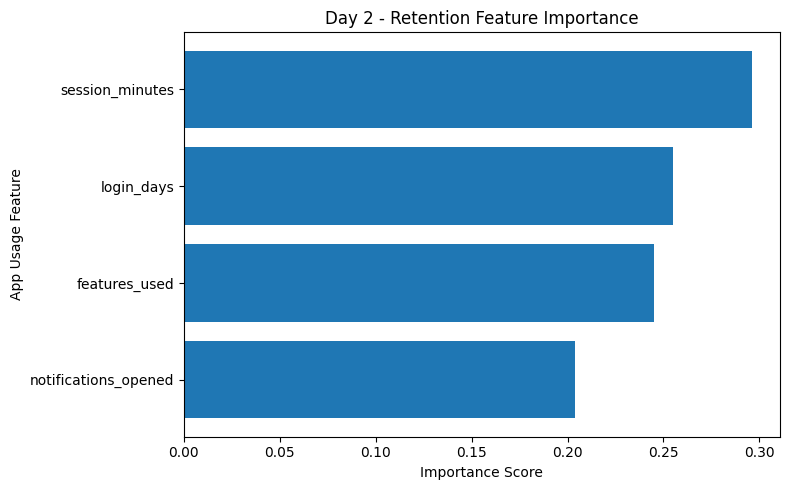

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained model
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": retention_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE")
display(importance)

# Visualize feature importance
plt.figure(figsize=(8, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("App Usage Feature")
plt.title("Day 2 - Retention Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [4]:

from textblob import TextBlob
import pandas as pd

# Sample mood journal history
journal_history = [
    {
        "day": "Day 1",
        "journal": "I enjoyed college and had a wonderful day."
    },
    {
        "day": "Day 2",
        "journal": "I had a normal day and completed my work."
    },
    {
        "day": "Day 3",
        "journal": "Today was difficult and frustrating."
    }
]

# Analyze each journal entry
results = []

for entry in journal_history:
    score = TextBlob(entry["journal"]).sentiment.polarity

    if score > 0.1:
        mood = "Positive"
    elif score < -0.1:
        mood = "Negative"
    else:
        mood = "Neutral"

    results.append({
        "Day": entry["day"],
        "Sentiment Score": round(score, 2),
        "Mood": mood
    })

mood_df = pd.DataFrame(results)

print("MOOD JOURNAL HISTORY")
display(mood_df)

# Compare consecutive entries
print("\nSENTIMENT SHIFT ANALYSIS")

for i in range(1, len(results)):
    previous_score = results[i - 1]["Sentiment Score"]
    current_score = results[i]["Sentiment Score"]

    print(f"{results[i-1]['Day']} -> {results[i]['Day']}")

    if current_score < previous_score - 0.2:
        print("Negative shift detected")
    else:
        print("No significant negative shift detected")


MOOD JOURNAL HISTORY


,Day,Sentiment Score,Mood
0,Day 1,0.75,Positive
1,Day 2,0.15,Positive
2,Day 3,-0.45,Negative



SENTIMENT SHIFT ANALYSIS
Day 1 -> Day 2
Negative shift detected
Day 2 -> Day 3
Negative shift detected


In [5]:
def safety_guardrail(journal):
    text = journal.lower()

    safety_keywords = [
        "suicide",
        "kill myself",
        "end my life",
        "self-harm"
    ]

    if any(keyword in text for keyword in safety_keywords):
        return (
            "Safety flag: Please reach out to a trusted person "
            "or a qualified support professional."
        )
    else:
        return "No safety keywords detected."

# Test with a normal journal entry
test_journal = "Today I enjoyed learning Python."
print(safety_guardrail(test_journal))

No safety keywords detected.


In [6]:
from textblob import TextBlob

def analyze_journal(journal):
    score = TextBlob(journal).sentiment.polarity

    if score > 0.1:
        mood = "Positive"
    elif score < -0.1:
        mood = "Negative"
    else:
        mood = "Neutral"

    safety_result = safety_guardrail(journal)

    print("Journal:", journal)
    print("Sentiment Score:", round(score, 2))
    print("Detected Mood:", mood)
    print("Safety Check:", safety_result)

# Test the function
analyze_journal("Today I enjoyed learning Python.")

Journal: Today I enjoyed learning Python.
Sentiment Score: 0.5
Detected Mood: Positive
Safety Check: No safety keywords detected.


In [7]:
previous_journal = "Today was a wonderful and happy day."
current_journal = "Today was terrible and very frustrating."

previous_score = TextBlob(previous_journal).sentiment.polarity
current_score = TextBlob(current_journal).sentiment.polarity

print("Previous Sentiment Score:", round(previous_score, 2))
print("Current Sentiment Score:", round(current_score, 2))

if current_score < previous_score - 0.2:
    print("Negative shift detected")
else:
    print("No significant negative shift detected")

Previous Sentiment Score: 0.9
Current Sentiment Score: -0.76
Negative shift detected


In [8]:
print("===== DAY 2 PROJECT SUMMARY =====")

print("\n1. App Usage Analysis: Completed")
print("2. Retention Model Training: Completed")
print("3. Model Evaluation: Completed")
print("4. Feature Importance Analysis: Completed")
print("5. Mood Journal History Analysis: Completed")
print("6. Safety Guardrail Check: Completed")
print("7. Negative Sentiment Shift Detection: Tested")

print("\nRetention Model Accuracy:", round(accuracy, 2))
print("\nDay 2 implementation completed successfully!")

===== DAY 2 PROJECT SUMMARY =====

1. App Usage Analysis: Completed
2. Retention Model Training: Completed
3. Model Evaluation: Completed
4. Feature Importance Analysis: Completed
5. Mood Journal History Analysis: Completed
6. Safety Guardrail Check: Completed
7. Negative Sentiment Shift Detection: Tested

Retention Model Accuracy: 1.0

Day 2 implementation completed successfully!
